# Wykrywanie, śledzenie i analiza ruchu osób

**Zespół:** Daniel Sterzel, Iwo Ropa, Anton Perakhod

Notebook pokazuje, jak działa system, i uruchamia go na trzech publicznych nagraniach z kamer stacjonarnych.

1. Jak działa system
2. Nagrania testowe
3. Uruchomienie
4. Wyniki dla każdego nagrania – śledzenie, trajektorie, mapa cieplna, kierunki i prędkość
5. ByteTrack vs BoT-SORT
6. Jak uruchomić poza notebookiem

> `Run All`. Pierwsze uruchomienie pobiera model YOLO (~5 MB) i nagrania (~45 MB); przetwarzanie trwa kilka minut na CPU.

## 1. Jak działa system

```
nagranie ──► YOLO ──────────────► tracker ─────────────────► analiza ruchu ─────────► wyniki
             ramki osób           ID każdej osoby            trajektorie, mapa         wideo z adnotacjami,
             + pewność            między klatkami            cieplna, linia, strefy    CSV, wykresy
```

**Wykrywanie – YOLO.** Sieć neuronowa, która w *jednym przebiegu* przez obraz zwraca prostokąty otaczające obiekty,
ich klasę i pewność. Model `yolo26n` (najmniejszy, działa w czasie rzeczywistym na CPU) jest wytrenowany na zbiorze COCO;
bierzemy tylko klasę `person`. **Pozycja osoby** = środek dolnej krawędzi ramki (punkt kontaktu stóp z podłożem).

**Śledzenie.** Detektor nie wie, że osoba w kolejnych klatkach to ta sama osoba. Tracker w każdej klatce:

1. przewiduje położenie każdego znanego śladu – **filtr Kalmana** (model stałej prędkości),
2. kojarzy przewidywania z nowymi detekcjami – miara **IoU** (stopień pokrycia ramek) i **algorytm węgierski**,
3. aktualizuje dopasowane ślady, tworzy nowe (nowe ID), usuwa ślady niewidoczne dłużej niż 30 klatek.

**ByteTrack** kojarzy w dwóch etapach: najpierw pewne detekcje (≥ 0.25), potem **niepewne** (0.1–0.25) z pozostałymi
śladami. Niepewne detekcje to często częściowo zasłonięte osoby – dzięki nim ślad się nie urywa. Dlatego próg detektora
w projekcie to 0.1. Używa tylko ruchu i IoU – jest bardzo szybki.

**BoT-SORT** – ta sama idea + dokładniejszy filtr Kalmana, kompensacja ruchu kamery i opcjonalnie cechy wyglądu (ReID).
Wolniejszy; przy kamerze stacjonarnej kompensacja ruchu niewiele daje.

**Analiza ruchu.**

* *trajektorie* – historia pozycji każdego ID: czas, droga, prostoliniowość, prędkość, kierunek,
* *mapa cieplna* – każda pozycja w każdej klatce zwiększa wartość miejsca (chłodne kolory = mało ruchu, ciepłe = dużo),
* *linia* – przejście = zmiana strony linii (znak iloczynu wektorowego), kierunek `in`/`out`, każde ID liczone raz,
* *strefa* – test „punkt w wielokącie”, liczba osób w strefie, wejścia i wyjścia.

| Moduł | Plik |
|---|---|
| Detekcja | `detection/yolo_detector.py` |
| Śledzenie | `tracking/person_tracker.py` |
| Analiza (na żywo) | `analysis/trajectories.py`, `heatmap.py`, `line_counter.py`, `zones.py` |
| Analiza trajektorii (offline) | `analysis/trajectory_analysis.py` |
| Rysowanie, wykresy | `visualization/drawing.py`, `visualization/plots.py` |
| Przetwarzanie klatki / nagrania | `pipeline.py`, `runner.py` |

## 2. Nagrania testowe

Trzy publiczne nagrania z kamer stacjonarnych, różniące się perspektywą i gęstością ruchu.
Dla każdego zdefiniowano linię zliczającą (żółta) i strefę (współrzędne jako ułamki szerokości/wysokości kadru).

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]  # zdjęcia w JPEG – mniejszy plik notebooka
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from analysis import LineCounter, ZoneMonitor
from analysis.trajectory_analysis import occupancy_heatmap, summarize_tracks
from runner import RunConfig, parse_line, parse_zone, run
from videos import TEST_VIDEOS, download_test_videos
from visualization import draw_line_counter, draw_zones
from visualization import plots

pd.set_option("display.precision", 2)
RESULTS = "data/results/notebook"


def show(fig):
    display(fig)
    plt.close(fig)


paths = download_test_videos()
pd.DataFrame({name: {"opis": info["description"], "linia": info["line"], "strefa": info["zones"][0],
                     "wejście YOLO [px]": info["image_size"]}
              for name, info in TEST_VIDEOS.items()}).T

,opis,linia,strefa,wejście YOLO [px]
people-walking.mp4,"hala, widok z góry, ~30 osób, 1920x1080, 25 FP...","0,0.5,1,0.5","srodek:0.35,0.3,0.65,0.8",640
market-square.mp4,"plac z fontanną, widok z góry, tłum, 2160x3840...","0,0.6,1,0.6","fontanna:0.3,0.25,0.75,0.45",1280
mot17-09.mp4,"deptak przy wejściu do sklepów, widok z boku, ...","0.55,0.35,0.55,1","wejscie:0.05,0.2,0.35,0.8",640


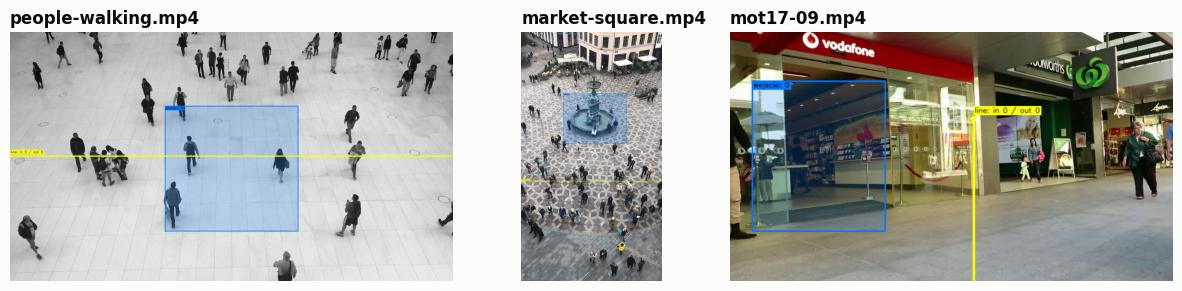

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6), gridspec_kw={"width_ratios": [16 / 9, 9 / 16, 16 / 9]})
for ax, (name, path) in zip(axes, paths.items()):
    capture = cv2.VideoCapture(str(path))
    ok, frame = capture.read()
    capture.release()
    size = (frame.shape[1], frame.shape[0])
    draw_zones(frame, ZoneMonitor([parse_zone(z, size, i) for i, z in enumerate(TEST_VIDEOS[name]["zones"])]))
    draw_line_counter(frame, LineCounter(*parse_line(TEST_VIDEOS[name]["line"], size)))
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.set_axis_off()
show(fig)

## 3. Uruchomienie

Każde nagranie przetwarzamy trackerem ByteTrack. Wyniki (CSV, mapa cieplna, wideo z adnotacjami)
trafiają do `data/results/notebook/`.

In [3]:
results, snapshots = {}, {}
for name, path in paths.items():
    total = int(cv2.VideoCapture(str(path)).get(cv2.CAP_PROP_FRAME_COUNT))

    def keep_middle_frame(annotated, stats, name=name, total=total):
        if stats.frame_index == total // 2:
            snapshots[name] = annotated

    results[name] = run(
        RunConfig(source=path, tracker="bytetrack", line=TEST_VIDEOS[name]["line"], zones=TEST_VIDEOS[name]["zones"],
                  image_size=TEST_VIDEOS[name]["image_size"], results_dir=RESULTS, output_video=f"{RESULTS}/{path.stem}_annotated.mp4"),
        on_frame=keep_middle_frame, progress=True,
    )

columns = ["resolution", "frames", "average_fps", "unique_people", "mean_people_in_frame",
           "max_people_in_frame", "line_in", "line_out", "zone_total_entries"]
pd.DataFrame({name: r.summary for name, r in results.items()}).loc[columns]

people-walking: 50/341 klatek

people-walking: 100/341 klatek

people-walking: 150/341 klatek

people-walking: 200/341 klatek

people-walking: 250/341 klatek

people-walking: 300/341 klatek

... (19 outputs left out)

mot17-09: 450/525 klatek

mot17-09: 500/525 klatek

mot17-09: 525/525 klatek

,people-walking.mp4,market-square.mp4,mot17-09.mp4
resolution,1920x1080,2160x3840,960x540
frames,341,474,525
average_fps,21.5,7.73,36.75
unique_people,75,159,66
mean_people_in_frame,26.77,58.18,9.01
max_people_in_frame,34,68,13
line_in,13,11,3
line_out,9,9,9
zone_total_entries,{'srodek': 15},{'fontanna': 10},{'wejscie': 25}


**Jak czytać tabelę:** `average_fps` – szybkość przetwarzania (CPU); `unique_people` – ile różnych ID nadał tracker
(zwykle więcej niż osób w rzeczywistości: gdy ślad się urwie, osoba dostaje nowe ID); `line_in/out` – przejścia
przez linię w obu kierunkach; `zone_total_entries` – wejścia do strefy.

### Wpływ rozmiaru wejścia YOLO

YOLO skaluje klatkę tak, by dłuższy bok miał `image_size` pikseli. Na nagraniu `market-square` (4K, widok z góry)
ludzie są bardzo mali: przy domyślnych 640 px sylwetka ma ok. 8×13 px i detektor prawie nikogo nie widzi.
Porównanie na pierwszych 60 klatkach:

In [4]:
rows = []
for size in (640, 1280, 1920):
    r = run(RunConfig(source=paths["market-square.mp4"], image_size=size, max_frames=60, results_dir=RESULTS + "/image_size"))
    rows.append({"image_size": size, "śr. osób w kadrze": r.summary["mean_people_in_frame"], "FPS": r.summary["average_fps"]})
pd.DataFrame(rows).set_index("image_size")

,śr. osób w kadrze,FPS
image_size,,
640,2.70,21.40
1280,55.98,12.16
1920,86.77,6.76


Większe wejście = więcej wykrytych małych postaci, ale wolniej. Dla tego nagrania używamy 1280 px (kompromis),
dla pozostałych domyślnych 640 px.

## 4. Wyniki dla każdego nagrania

### people-walking.mp4

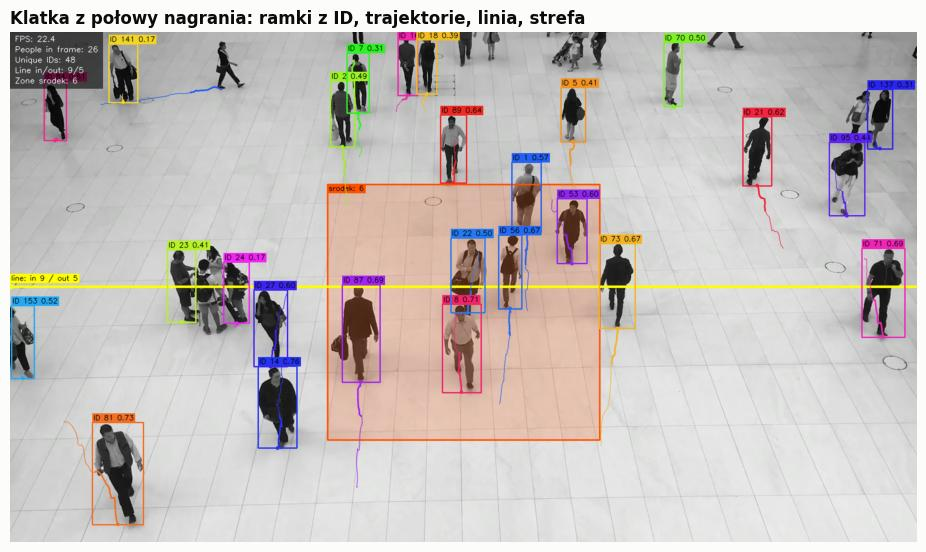

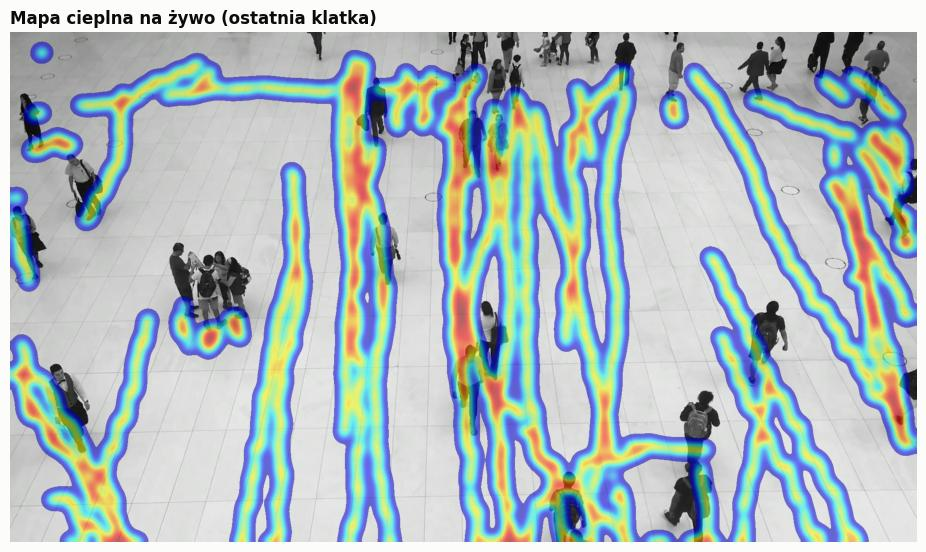

In [5]:
r = results["people-walking.mp4"]
width = 10 if r.frame_size[0] > r.frame_size[1] else 5
show(plots.show_image(snapshots["people-walking.mp4"], "Klatka z połowy nagrania: ramki z ID, trajektorie, linia, strefa", width))
show(plots.show_image(r.heatmap_image, "Mapa cieplna na żywo (ostatnia klatka)", width))

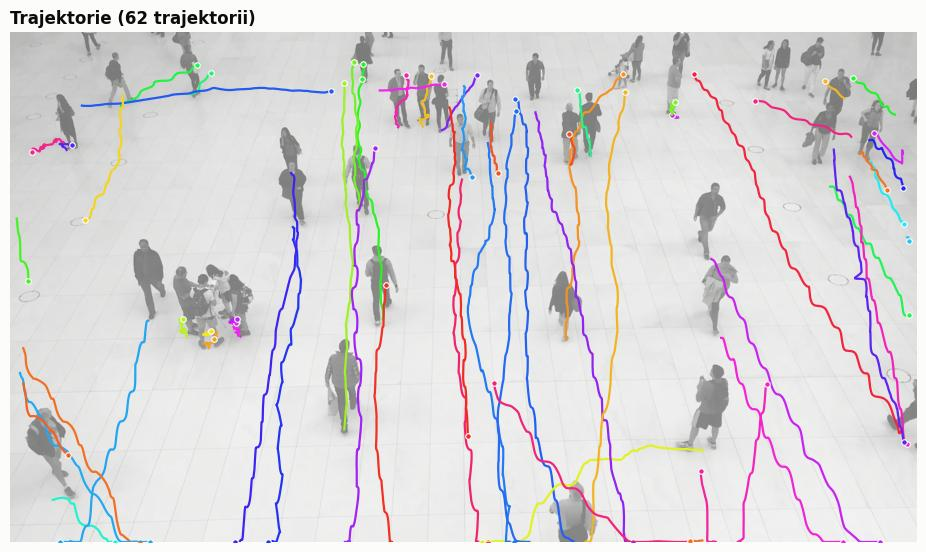

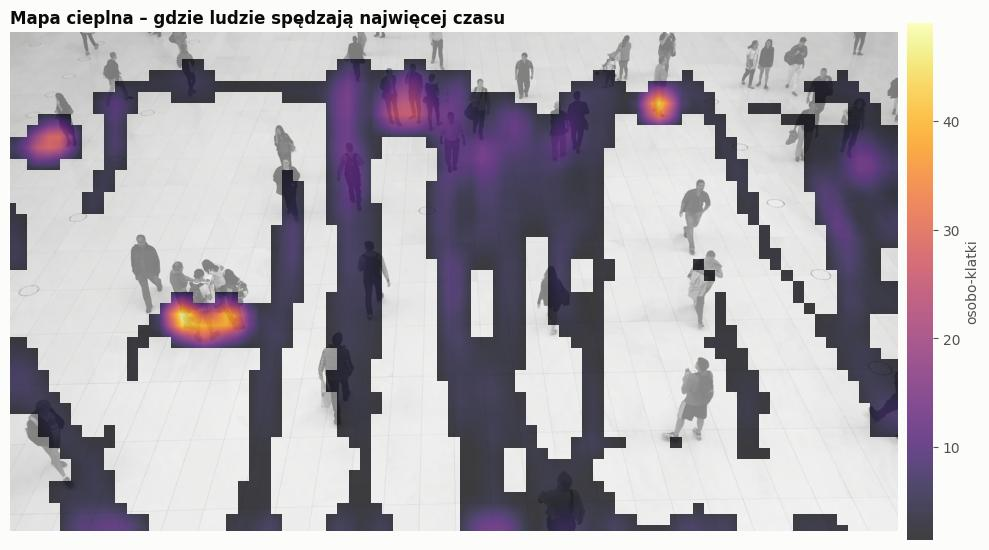

In [6]:
cell = max(r.frame_size) // 80
show(plots.plot_trajectories(r.tracks, r.frame_size, r.first_frame, width_in=width))
show(plots.plot_heatmap(occupancy_heatmap(r.tracks, r.frame_size, cell), r.frame_size, r.first_frame, cell=cell,
                        title="Mapa cieplna – gdzie ludzie spędzają najwięcej czasu", width_in=width))

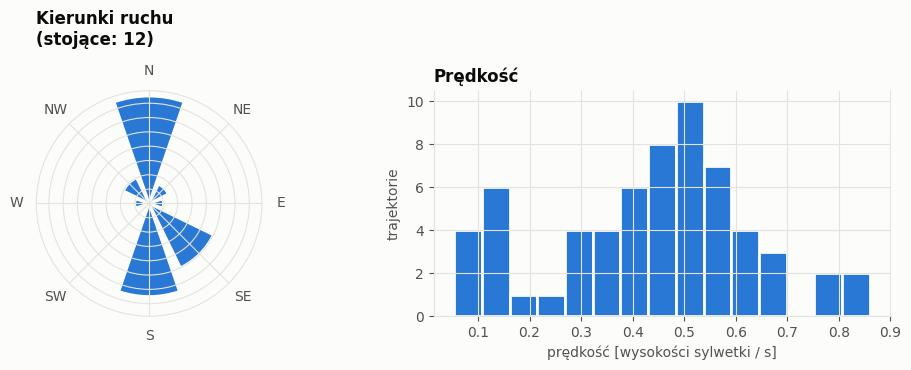

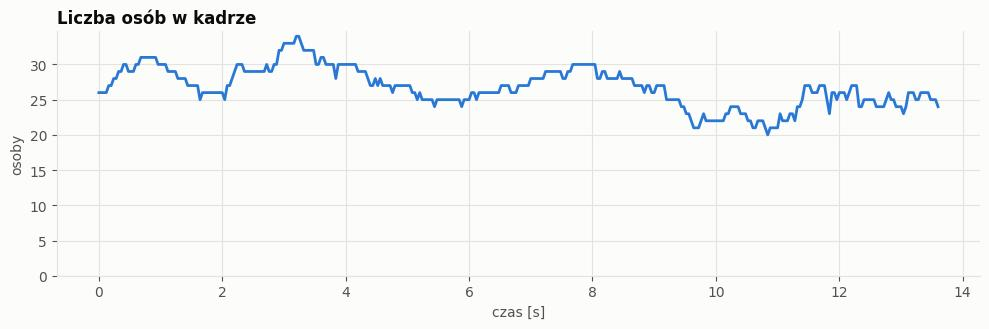

,duration_s,path_length_px,straightness,speed_heights_s
count,62.00,62.00,62.00,62.00
mean,5.93,379.02,0.83,0.43
50%,5.14,207.65,0.92,0.46
max,13.64,1003.94,0.99,0.86


In [7]:
summary = summarize_tracks(r.tracks, r.fps)
fig = plt.figure(figsize=(10, 3.8))
plots.plot_direction_rose(summary, ax=fig.add_subplot(1, 2, 1, projection="polar"))
plots.plot_speed_histogram(summary, ax=fig.add_subplot(1, 2, 2))
fig.tight_layout()
show(fig)
show(plots.plot_people_over_time({"people-walking.mp4": r.stats}))
summary[["duration_s", "path_length_px", "straightness", "speed_heights_s"]].describe().loc[["count", "mean", "50%", "max"]]

### market-square.mp4

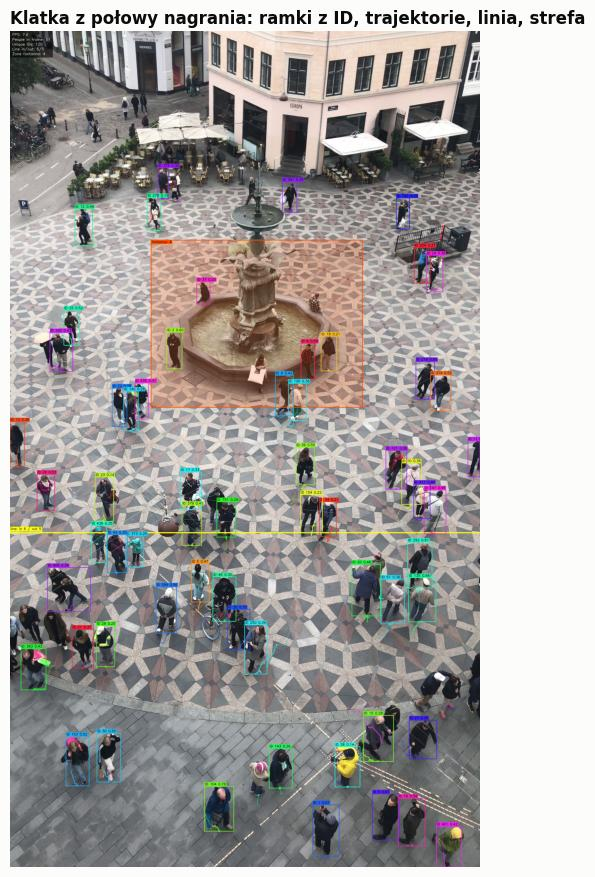

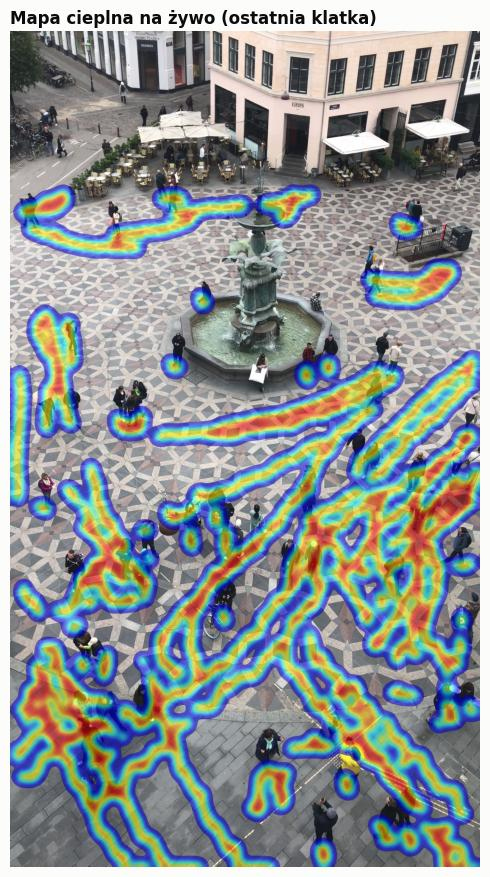

In [8]:
r = results["market-square.mp4"]
width = 10 if r.frame_size[0] > r.frame_size[1] else 5
show(plots.show_image(snapshots["market-square.mp4"], "Klatka z połowy nagrania: ramki z ID, trajektorie, linia, strefa", width))
show(plots.show_image(r.heatmap_image, "Mapa cieplna na żywo (ostatnia klatka)", width))

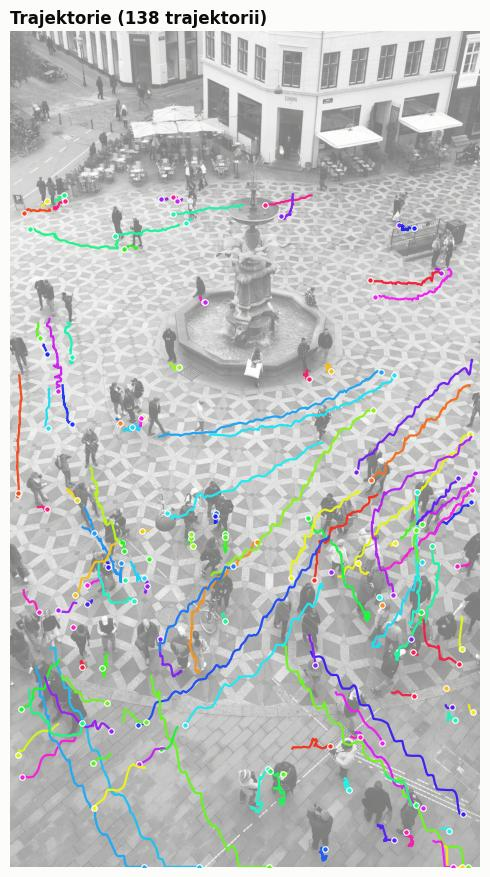

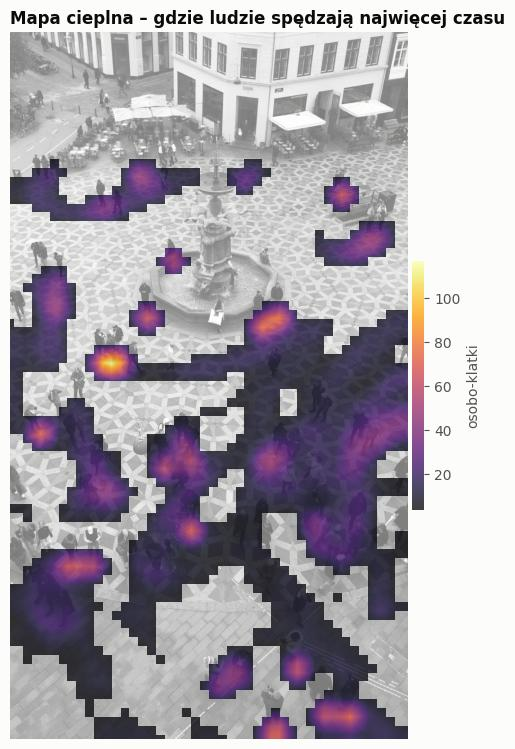

In [9]:
cell = max(r.frame_size) // 80
show(plots.plot_trajectories(r.tracks, r.frame_size, r.first_frame, width_in=width))
show(plots.plot_heatmap(occupancy_heatmap(r.tracks, r.frame_size, cell), r.frame_size, r.first_frame, cell=cell,
                        title="Mapa cieplna – gdzie ludzie spędzają najwięcej czasu", width_in=width))

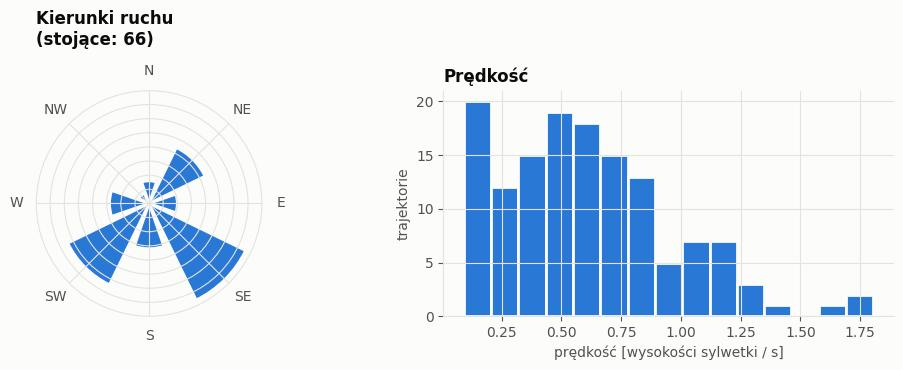

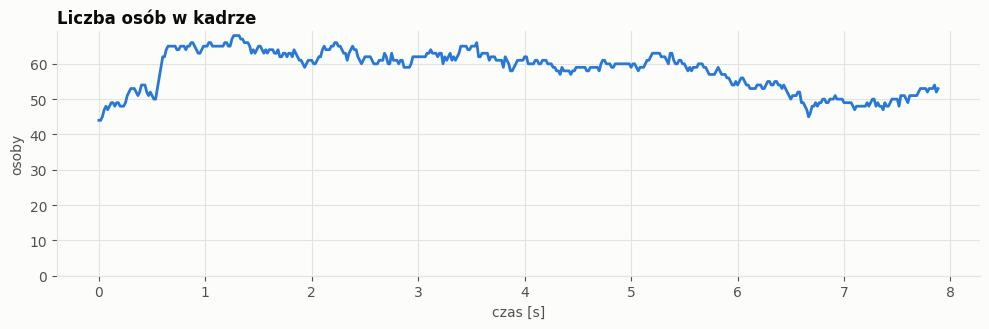

,duration_s,path_length_px,straightness,speed_heights_s
count,138.00,138.00,138.00,138.00
mean,3.39,340.19,0.62,0.61
50%,2.37,211.59,0.73,0.58
max,7.90,1711.26,0.99,1.81


In [10]:
summary = summarize_tracks(r.tracks, r.fps)
fig = plt.figure(figsize=(10, 3.8))
plots.plot_direction_rose(summary, ax=fig.add_subplot(1, 2, 1, projection="polar"))
plots.plot_speed_histogram(summary, ax=fig.add_subplot(1, 2, 2))
fig.tight_layout()
show(fig)
show(plots.plot_people_over_time({"market-square.mp4": r.stats}))
summary[["duration_s", "path_length_px", "straightness", "speed_heights_s"]].describe().loc[["count", "mean", "50%", "max"]]

### mot17-09.mp4

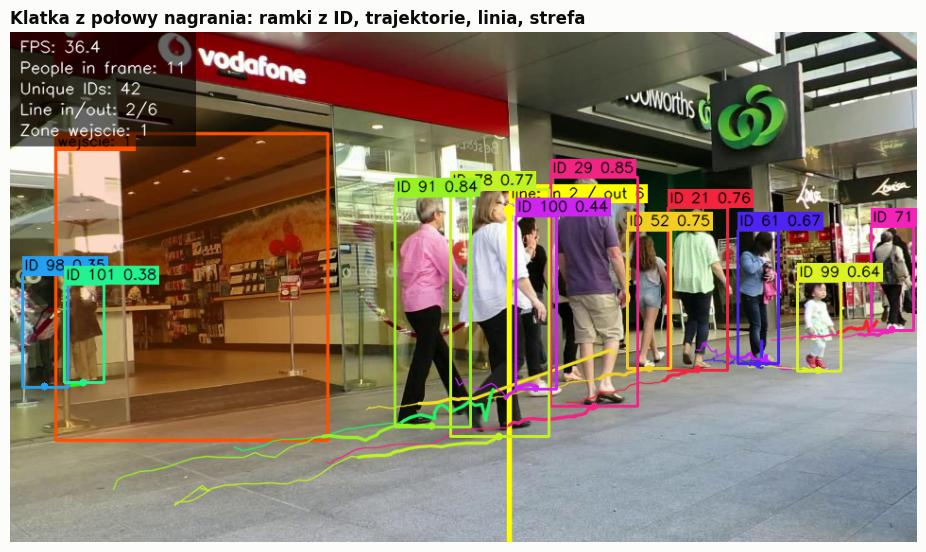

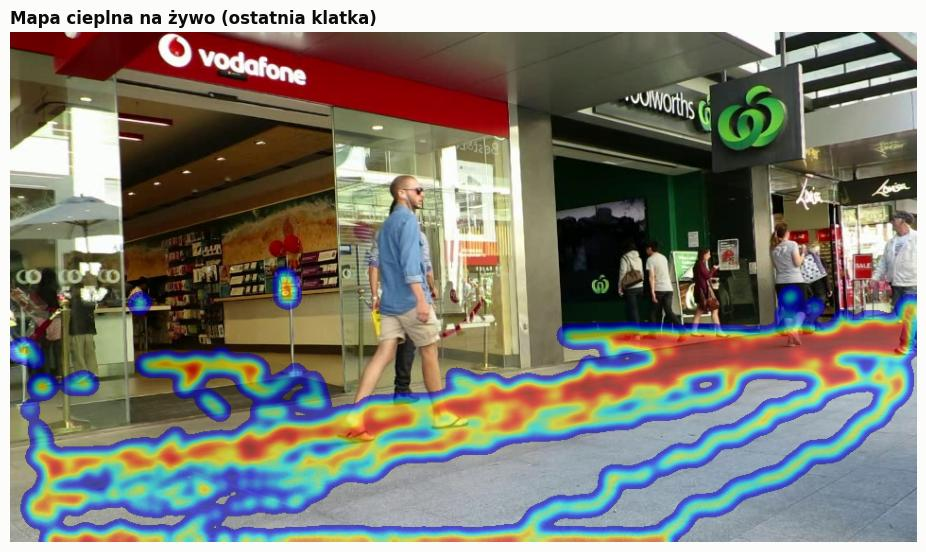

In [11]:
r = results["mot17-09.mp4"]
width = 10 if r.frame_size[0] > r.frame_size[1] else 5
show(plots.show_image(snapshots["mot17-09.mp4"], "Klatka z połowy nagrania: ramki z ID, trajektorie, linia, strefa", width))
show(plots.show_image(r.heatmap_image, "Mapa cieplna na żywo (ostatnia klatka)", width))

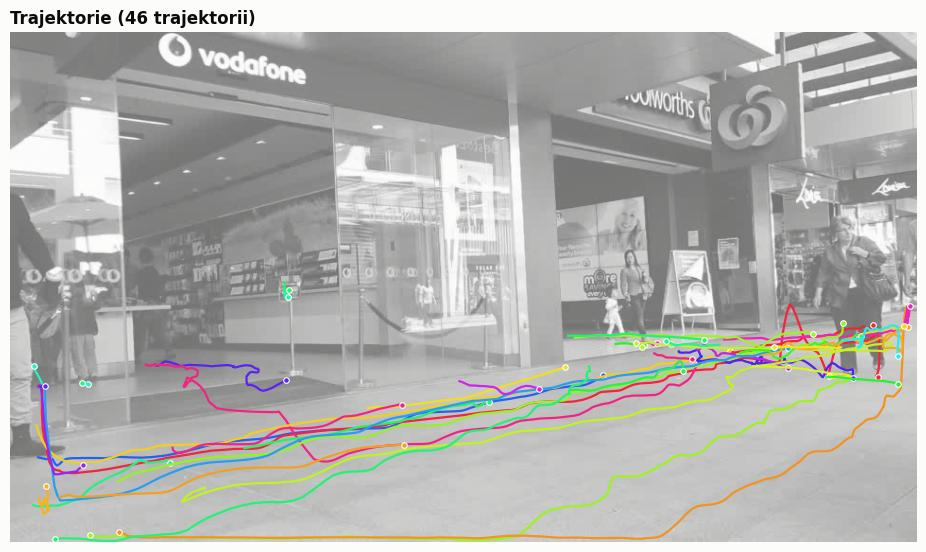

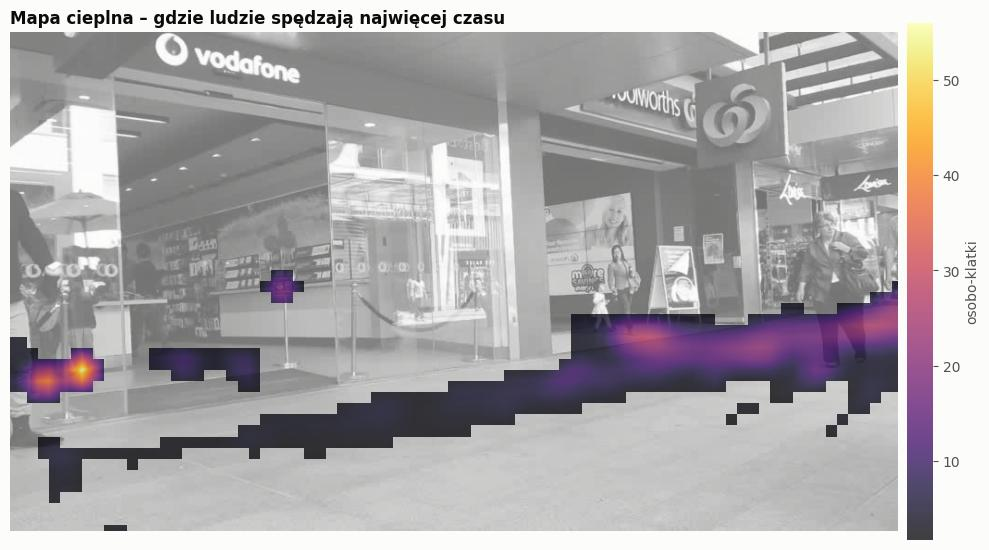

In [12]:
cell = max(r.frame_size) // 80
show(plots.plot_trajectories(r.tracks, r.frame_size, r.first_frame, width_in=width))
show(plots.plot_heatmap(occupancy_heatmap(r.tracks, r.frame_size, cell), r.frame_size, r.first_frame, cell=cell,
                        title="Mapa cieplna – gdzie ludzie spędzają najwięcej czasu", width_in=width))

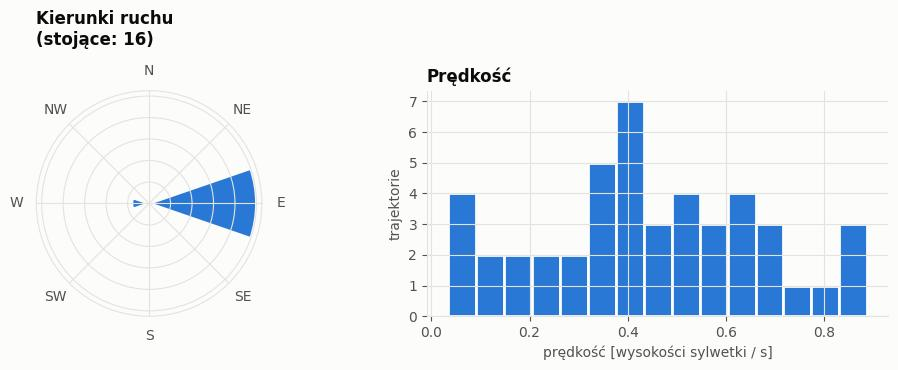

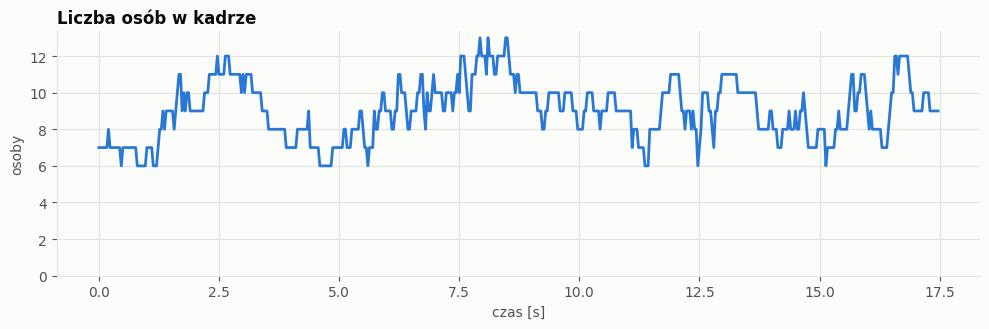

,duration_s,path_length_px,straightness,speed_heights_s
count,46.00,46.00,46.00,46.00
mean,3.74,283.57,0.73,0.44
50%,2.73,144.66,0.89,0.42
max,11.20,1200.03,1.00,0.89


In [13]:
summary = summarize_tracks(r.tracks, r.fps)
fig = plt.figure(figsize=(10, 3.8))
plots.plot_direction_rose(summary, ax=fig.add_subplot(1, 2, 1, projection="polar"))
plots.plot_speed_histogram(summary, ax=fig.add_subplot(1, 2, 2))
fig.tight_layout()
show(fig)
show(plots.plot_people_over_time({"mot17-09.mp4": r.stats}))
summary[["duration_s", "path_length_px", "straightness", "speed_heights_s"]].describe().loc[["count", "mean", "50%", "max"]]

Prędkość jest podana w **wysokościach sylwetki na sekundę**: bez kalibracji kamery piksele nie są metrami, a osoby
daleko od kamery przesuwają się o mniej pikseli. Przy wzroście ~1.7 m wartość 1.0 ≈ 1.7 m/s.
`straightness` = przemieszczenie / przebyta droga (1 = ruch po linii prostej).

## 5. ByteTrack vs BoT-SORT

Te same nagrania, ten sam detektor – zmienia się tylko tracker. Mniej unikalnych ID przy tej samej scenie
oznacza zwykle stabilniejsze śledzenie (mniej urwanych śladów).

In [14]:
rows = []
for name, path in paths.items():
    botsort = run(RunConfig(source=path, tracker="botsort", line=TEST_VIDEOS[name]["line"],
                            image_size=TEST_VIDEOS[name]["image_size"], results_dir=RESULTS),
                  progress=True)
    for tracker, r in [("ByteTrack", results[name]), ("BoT-SORT", botsort)]:
        rows.append({"nagranie": name, "tracker": tracker, "FPS": r.summary["average_fps"],
                     "unikalne ID": r.summary["unique_people"],
                     "śr. długość śladu [s]": summarize_tracks(r.tracks, r.fps, min_frames=1)["duration_s"].mean(),
                     "linia in/out": f'{r.summary["line_in"]}/{r.summary["line_out"]}'})
pd.DataFrame(rows).set_index(["nagranie", "tracker"])

people-walking: 50/341 klatek

people-walking: 100/341 klatek

people-walking: 150/341 klatek

people-walking: 200/341 klatek

people-walking: 250/341 klatek

people-walking: 300/341 klatek

... (19 outputs left out)

mot17-09: 450/525 klatek

mot17-09: 500/525 klatek

mot17-09: 525/525 klatek

FPS  unikalne ID  śr. długość śladu [s]  \
nagranie           tracker                                                
people-walking.mp4 ByteTrack  21.50           75                   4.95   
                   BoT-SORT   23.23           71                   5.26   
market-square.mp4  ByteTrack   7.73          159                   2.96   
                   BoT-SORT    7.95          152                   3.11   
mot17-09.mp4       ByteTrack  36.75           66                   2.67   
                   BoT-SORT   34.11           66                   2.61   

                             linia in/out  
nagranie           tracker                 
people-walking.mp4 ByteTrack         13/9  
                   BoT-SORT          13/9  
market-square.mp4  ByteTrack         11/9  
                   BoT-SORT          12/9  
mot17-09.mp4       ByteTrack          3/9  
                   BoT-SORT           3/8

## 6. Jak uruchomić poza notebookiem

```
python -m pip install -r requirements.txt
python videos.py                                   # pobranie nagrań testowych
python main.py data/videos/people-walking.mp4 --show --heatmap --line 0,0.5,1,0.5 --zone srodek:0.35,0.3,0.65,0.8
python main.py 0 --show                            # kamera internetowa
python -m unittest discover -s tests -t .          # testy
```

W oknie podglądu: `q` – wyjście, `h` – włącz/wyłącz mapę cieplną.